In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/ieee-fraud-detection/sample_submission.csv
/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv
/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df_sample = pd.read_csv("/kaggle/input/competitions/ieee-fraud-detection/sample_submission.csv")
test_i = pd.read_csv("/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv")
train_i = pd.read_csv("/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv")
test_t = pd.read_csv("/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv")
train_t = pd.read_csv("/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv")

In [6]:
print(df_sample.shape, test_i.shape, train_i.shape, test_t.shape, train_t.shape)

(506691, 2) (141907, 41) (144233, 41) (506691, 393) (590540, 394)


In [7]:
df_sample.head()

,TransactionID,isFraud
0,3663549,0.5
1,3663550,0.5
2,3663551,0.5
3,3663552,0.5
4,3663553,0.5


In [10]:
train_i.head()


,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [23]:
train_i.describe().sum

<bound method DataFrame.sum of        TransactionID          id_01          id_02         id_03  \
count   1.442330e+05  144233.000000  140872.000000  66324.000000   
mean    3.236329e+06     -10.170502  174716.584708      0.060189   
std     1.788496e+05      14.347949  159651.816856      0.598231   
min     2.987004e+06    -100.000000       1.000000    -13.000000   
25%     3.077142e+06     -10.000000   67992.000000      0.000000   
50%     3.198818e+06      -5.000000  125800.500000      0.000000   
75%     3.392923e+06      -5.000000  228749.000000      0.000000   
max     3.577534e+06       0.000000  999595.000000     10.000000   

              id_04          id_05          id_06        id_07        id_08  \
count  66324.000000  136865.000000  136865.000000  5155.000000  5155.000000   
mean      -0.058938       1.615585      -6.698710    13.285354   -38.600388   
std        0.701015       5.249856      16.491104    11.384207    26.084899   
min      -28.000000     -72.000000    -1

In [27]:
print(train_i.isnull().sum()*100/train_i.count().sum())

TransactionID    0.000000
id_01            0.000000
id_02            0.088228
id_03            2.045153
id_04            2.045153
id_05            0.193414
id_06            0.193414
id_07            3.650872
id_08            3.650872
id_09            1.819346
id_10            1.819346
id_11            0.085445
id_12            0.000000
id_13            0.443975
id_14            1.684996
id_15            0.085262
id_16            0.390949
id_17            0.127683
id_18            2.601953
id_19            0.129021
id_20            0.130518
id_21            3.650767
id_22            3.650505
id_23            3.650505
id_24            3.661582
id_25            3.651476
id_26            3.650662
id_27            3.650505
id_28            0.085445
id_29            0.085445
id_30            1.750071
id_31            0.103716
id_32            1.749519
id_33            1.862318
id_34            1.743771
id_35            0.085262
id_36            0.085262
id_37            0.085262
id_38       

In [28]:
train_t.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [29]:
train_t.describe().sum

<bound method DataFrame.sum of        TransactionID        isFraud  TransactionDT  TransactionAmt  \
count   5.905400e+05  590540.000000   5.905400e+05   590540.000000   
mean    3.282270e+06       0.034990   7.372311e+06      135.027176   
std     1.704744e+05       0.183755   4.617224e+06      239.162522   
min     2.987000e+06       0.000000   8.640000e+04        0.251000   
25%     3.134635e+06       0.000000   3.027058e+06       43.321000   
50%     3.282270e+06       0.000000   7.306528e+06       68.769000   
75%     3.429904e+06       0.000000   1.124662e+07      125.000000   
max     3.577539e+06       1.000000   1.581113e+07    31937.391000   

               card1          card2          card3          card5  \
count  590540.000000  581607.000000  588975.000000  586281.000000   
mean     9898.734658     362.555488     153.194925     199.278897   
std      4901.170153     157.793246      11.336444      41.244453   
min      1000.000000     100.000000     100.000000     100.000

In [32]:
print((train_t.isnull().sum()*100/train_i.count().sum()).sort_values(ascending=False))

dist2             14.514263
D7                14.480400
D13               13.875718
D14               13.869550
D12               13.803136
                    ...    
ProductCD          0.000000
TransactionAmt     0.000000
TransactionDT      0.000000
isFraud            0.000000
TransactionID      0.000000
Length: 394, dtype: float64


In [33]:
# Select numerical columns
num_df = train_t.select_dtypes(include=np.number)

# Calculate correlation of every numerical feature with isFraud
corr = num_df.corr()["isFraud"].drop("isFraud")

# Sort by absolute correlation, highest first
corr = corr.loc[corr.abs().sort_values(ascending=False).index]

print(corr)

V257    0.383060
V246    0.366878
V244    0.364129
V242    0.360590
V201    0.328005
          ...   
V299   -0.000308
V135   -0.000276
V137   -0.000115
V319    0.000061
V136   -0.000042
Name: isFraud, Length: 379, dtype: float64


In [34]:
import numpy as np
import pandas as pd

# Select numerical features, excluding the target and transaction ID
X = train_t.drop(
    columns=["isFraud", "TransactionID"],
    errors="ignore"
).select_dtypes(include=np.number)

# Calculate the feature-to-feature correlation matrix
corr_matrix = X.corr().abs()

# Keep only the upper triangle to avoid duplicate pairs
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find pairs with absolute correlation above 0.95
high_corr_pairs = (
    upper.stack()
    .loc[lambda s: s > 0.95]
    .sort_values(ascending=False)
)

print(high_corr_pairs)

D4    D12     0.999999
V95   V322    0.999949
V96   V323    0.999948
V97   V324    0.999947
V101  V322    0.999698
                ...   
V128  V212    0.950472
V317  V322    0.950366
V329  V333    0.950356
V148  V149    0.950232
V96   V329    0.950165
Length: 573, dtype: float64


In [37]:
# Separate features from target
X = train_t.drop(
    columns=["isFraud", "TransactionID"],
    errors="ignore"
).select_dtypes(include=np.number)

# Calculate absolute correlation between features
corr_matrix = X.corr().abs()

# Select the upper triangle
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Identify candidate features for removal
threshold = 0.95

to_drop = [
    col for col in upper.columns
    if (upper[col] > threshold).any()
]

print("Original numerical features:", X.shape[1])
print("Candidate features to remove:", len(to_drop))

Original numerical features: 378
Candidate features to remove: 136


In [38]:
# Dataset containing all numerical features
X_all = X.copy()

# Dataset with highly correlated features removed
X_reduced = X.drop(columns=to_drop)

y = train_t["isFraud"]

print("All features:", X_all.shape)
print("Reduced features:", X_reduced.shape)

All features: (590540, 378)
Reduced features: (590540, 242)


In [39]:
from sklearn.model_selection import train_test_split

X_train_all, X_val_all, y_train, y_val = train_test_split(
    X_all,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train_reduced = X_train_all.drop(
    columns=to_drop,
    errors="ignore"
)

X_val_reduced = X_val_all.drop(
    columns=to_drop,
    errors="ignore"
)

print("Training samples:", X_train_all.shape[0])
print("Validation samples:", X_val_all.shape[0])

Training samples: 472432
Validation samples: 118108


In [40]:
%pip install -q lightgbm

Note: you may need to restart the kernel to use updated packages.


In [41]:
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

model_all = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

model_all.fit(X_train_all, y_train)

pred_all = model_all.predict_proba(X_val_all)[:, 1]

auc_all = roc_auc_score(y_val, pred_all)

print("ROC-AUC with all features:", auc_all)

ROC-AUC with all features: 0.9412781634899304


In [42]:
model_reduced = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

model_reduced.fit(X_train_reduced, y_train)

pred_reduced = model_reduced.predict_proba(X_val_reduced)[:, 1]

auc_reduced = roc_auc_score(y_val, pred_reduced)

print("ROC-AUC with all features:", auc_all)
print("ROC-AUC with reduced features:", auc_reduced)
print("Difference:", auc_reduced - auc_all)

ROC-AUC with all features: 0.9412781634899304
ROC-AUC with reduced features: 0.9398861468796853
Difference: -0.0013920166102451281


In [43]:
feature_importance = pd.DataFrame({
    "Feature": X_train_all.columns,
    "Importance": model_all.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance.head(30))

,Feature,Importance
3,card2,906
2,card1,848
0,TransactionDT,771
6,addr1,679
1,TransactionAmt,581
5,card5,379
38,D15,377
22,C13,368
10,C1,290
25,D2,285


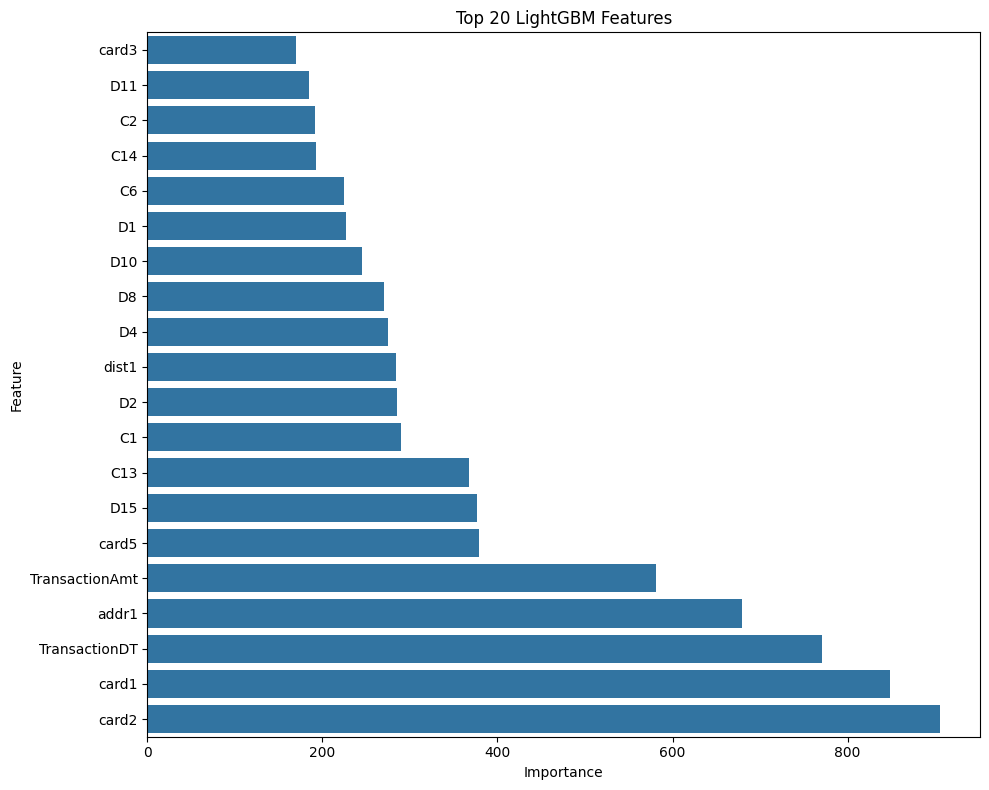

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

top20 = feature_importance.head(20).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top20,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 LightGBM Features")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd

perm = permutation_importance(
    model_all,
    X_val_all,
    y_val,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

perm_importance = pd.DataFrame({
    "Feature": X_val_all.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
})

perm_importance = perm_importance.sort_values(
    "Importance",
    ascending=False
)

display(perm_importance.head(20))

In [ ]:
from sklearn.metrics import roc_auc_score

print(
    "Validation ROC-AUC:",
    roc_auc_score(y_val, model_all.predict_proba(X_val_all)[:, 1])
)